# SAT-Mat · Implementación del Sistema de Alerta Temprana de Rezago en Matemáticas
**SCY1102 Gestión de Proyectos de Datos · Grupo 6** — Arelis Tovar, Dayana Vega, Encar Portillo

Notebook de implementación técnica del plan (Evaluación 3). Sigue las fases CRISP-DM del plan y deja evidencia ejecutada de cada una:

| Sección | Fase CRISP-DM | Paquetes WBS | Entregable |
|---|---|---|---|
| 1 | Comprensión de los datos | 1.3.1, 1.3.2 | E3 |
| 2 | Preparación de los datos | 1.3.3–1.3.5 | E4 · H2 |
| 3 | Modelado | 1.4.1–1.4.4 | E5 |
| 4 | Evaluación (desempeño y equidad) | 1.5.1, 1.5.2, 1.5.4 | E6 · H3 |
| 5 | Explicabilidad SHAP | 1.4.4 | E6 |
| 6 | Despliegue por lotes (nómina de alertas) | 1.6.2, 1.6.3 | E7 |
| 7 | Predicciones con datos nuevos | — | E7 |
| 8 | Automatización: alerta, deriva y reentrenamiento | 1.6.3 | E7 |
| 9 | Registro de avance técnico | 1.1.4 | — |
| 10 | Cumplimiento de requerimientos | — | — |

**Datos.** El caso entrega tres archivos (`train`, `validation`, `test`). `train.csv` superó el límite de carga del entorno de trabajo, por lo que se entrena con `validation.csv` (≈1 millón de filas) y se reserva `test.csv` (≈1 millón de filas) como conjunto de prueba independiente que no se usa para ninguna decisión de modelado (registrado como cambio CC-01 en el control del proyecto).

### Cómo ejecutar este notebook
**En Google Colab**
1. En Google Drive, tener una carpeta `SAT-Mat` con una subcarpeta `data` que contenga `validation.csv` y `test.csv` (puede estar en «Mi unidad» o en «Compartido conmigo»).
2. Abrir este notebook en Colab (*Archivo › Subir notebook*).
3. Ejecutar *Entorno de ejecución › Ejecutar todas*. La celda siguiente instala `shap`, pide autorizar el acceso a Drive, encuentra la carpeta y copia los dos CSV a `/content/SAT-Mat/data`. Los resultados quedan en `/content/SAT-Mat/outputs` (se borran al cerrar Colab: descárgalos desde el panel de archivos).

**En Jupyter local**: dejar `validation.csv` y `test.csv` en una carpeta `data/` junto al notebook; la celda siguiente no hace nada.

Los resultados se guardan en `outputs/` y los gráficos en `figs/`. Tiempo aproximado: 5–8 minutos (Random Forest es lo más lento).

In [ ]:
# Configuraci�n para Google Colab y Jupyter Local
# Detecta el entorno y configura carga de datos autom�ticamente

import os
import sys

# Detectar si estamos en Colab
try:
    import google.colab
    EN_COLAB = True
except ImportError:
    EN_COLAB = False

print(f'Entorno: {"Google Colab" if EN_COLAB else "Jupyter Local"}')
print("-" * 60)

if EN_COLAB:
    # --- GOOGLE COLAB ---
    print('Google Colab detectado. Configurando acceso a Drive...')
    
    get_ipython().system('pip -q install shap')  # Instalar SHAP si falta
    
    import io
    from google.colab import auth
    from googleapiclient.discovery import build
    from googleapiclient.http import MediaIoBaseDownload
    
    # Autorizar
    print('Paso 1: Autorizando acceso a Google Drive...')
    auth.authenticate_user()
    srv = build('drive', 'v3')
    
    # Funciones auxiliares
    def buscar(q):
        return srv.files().list(
            q=q + " and trashed=false",
            fields='files(id,name)',
            includeItemsFromAllDrives=True,
            supportsAllDrives=True,
            pageSize=100
        ).execute().get('files', [])
    
    # Buscar carpeta SAT-Mat y subcarpeta data
    print('Paso 2: Buscando carpeta SAT-Mat en tu Drive...')
    CARPETA = "mimeType='application/vnd.google-apps.folder'"
    data_id = None
    
    for c in buscar(f"name='SAT-Mat' and {CARPETA}"):
        sub = buscar(f"name='data' and '{c['id']}' in parents and {CARPETA}")
        if sub:
            data_id = sub[0]['id']
            print(f'  ? Carpeta SAT-Mat/data encontrada')
            break
    
    assert data_id, "? No encontr� SAT-Mat/data. Crea en Drive: SAT-Mat � data, copia CSV ah�"
    
    # Preparar directorio de trabajo
    os.makedirs('/content/SAT-Mat/data', exist_ok=True)
    os.chdir('/content/SAT-Mat')
    DATA_PATH = 'data'
    
    # Descargar CSV
    print('Paso 3: Descargando archivos de Drive...')
    for nombre in ['validation.csv', 'test.csv']:
        ruta = f'{DATA_PATH}/{nombre}'
        
        if not os.path.exists(ruta):
            archivos = buscar(f"name='{nombre}' and '{data_id}' in parents")
            assert archivos, f"? Falta {nombre} en SAT-Mat/data"
            
            print(f'  Descargando {nombre}...', end=' ')
            req = srv.files().get_media(fileId=archivos[0]['id'], supportsAllDrives=True)
            with io.FileIO(ruta, 'wb') as fh:
                dl, listo = MediaIoBaseDownload(fh, req, chunksize=50 * 1024 * 1024), False
                while not listo:
                    _, listo = dl.next_chunk()
        
        tamano_mb = os.path.getsize(ruta) / 1e6
        print(f'? {nombre}: {tamano_mb:.0f} MB')
    
    print(f'? Listo. Directorio: {os.getcwd()}')

else:
    # --- JUPYTER LOCAL ---
    print('Jupyter Local detectado.')
    
    if not os.path.exists('data'):
        print("? Carpeta 'data' no encontrada.")
        print("Soluci�n: crear carpeta data/ y copiar validation.csv y test.csv")
        sys.exit(1)
    
    DATA_PATH = 'data'
    
    for nombre in ['validation.csv', 'test.csv']:
        ruta = f'{DATA_PATH}/{nombre}'
        if not os.path.exists(ruta):
            print(f"? Falta archivo: {ruta}")
            sys.exit(1)
        tamano_mb = os.path.getsize(ruta) / 1e6
        print(f'? {nombre}: {tamano_mb:.0f} MB')
    
    print(f'? Listo. Directorio: {os.getcwd()}')

print("-" * 60)


In [2]:
import os, time, json, hashlib, platform, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import sklearn, xgboost as xgb, shap, joblib
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import (roc_auc_score, precision_recall_curve, precision_score,
                             recall_score, f1_score, confusion_matrix, roc_curve)
warnings.filterwarnings('ignore')

SEED = 42
np.random.seed(SEED)
DATA, OUT, FIG = 'data', 'outputs', 'figs'
os.makedirs(OUT, exist_ok=True); os.makedirs(FIG, exist_ok=True)

# Estilo de figuras (paleta validada: azul, naranjo, aqua; tinta neutra)
AZUL, NARANJO, AQUA, GRIS, TINTA = '#2a78d6', '#eb6834', '#1baf7a', '#9a9893', '#0b0b0b'
plt.rcParams.update({'figure.dpi': 110, 'savefig.dpi': 200, 'font.size': 10,
                     'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.edgecolor': '#c9c8c3', 'axes.labelcolor': '#52514e',
                     'xtick.color': '#52514e', 'ytick.color': '#52514e',
                     'axes.grid': True, 'grid.color': '#ecebe7', 'grid.linewidth': 0.8,
                     'axes.titleweight': 'bold', 'axes.titlesize': 11})

print('Python', platform.python_version(), '| pandas', pd.__version__, '| scikit-learn', sklearn.__version__,
      '| xgboost', xgb.__version__, '| shap', shap.__version__)

Python 3.13.18 | pandas 3.0.5 | scikit-learn 1.9.1 | xgboost 3.4.1 | shap 0.54.1


/usr/local/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Comprensión de los datos (WBS 1.3.1–1.3.2 · E3)
Carga, perfilamiento de calidad (nulos, duplicados, rangos) y verificación de los supuestos del plan (S1, RD-01, RD-03).

In [3]:
t0 = time.time()
train_raw = pd.read_csv(f'{DATA}/validation.csv')   # conjunto de entrenamiento
test_raw  = pd.read_csv(f'{DATA}/test.csv')         # conjunto de prueba independiente
print(f'Carga: {time.time()-t0:.1f} s')
print('Entrenamiento:', train_raw.shape, '| Prueba:', test_raw.shape)
train_raw.head()

Carga: 3.4 s
Entrenamiento: (999229, 21) | Prueba: (999997, 21)


,Age,Grade,Gender,Race,SES_Quartile,ParentalEducation,SchoolType,Locale,TestScore_Math,TestScore_Reading,...,GPA,AttendanceRate,StudyHours,InternetAccess,Extracurricular,PartTimeJob,ParentSupport,Romantic,FreeTime,GoOut
0,14,9,Female,Hispanic,3,SomeCollege,Public,City,90.186244,88.390291,...,3.509322,0.964022,1.409700,1,1,0,0,0,1,4
1,17,12,Female,White,4,SomeCollege,Public,Rural,73.356297,73.471428,...,3.118458,0.882988,1.112296,1,0,0,1,0,3,3
2,17,12,Female,Other,2,HS,Public,Suburban,73.970459,76.085029,...,3.640436,0.864401,1.214927,1,1,1,1,1,1,1
3,15,10,Male,White,4,SomeCollege,Public,Suburban,64.500290,63.858629,...,2.990611,0.887791,0.155258,1,0,0,1,0,5,4
4,18,12,Male,Black,3,HS,Public,City,84.546267,88.502675,...,3.546262,0.933201,0.908776,1,1,0,0,1,3,3


In [4]:
def perfil(df):
    return pd.DataFrame({'tipo': df.dtypes.astype(str), 'nulos_%': (df.isna().mean()*100).round(2),
                         'únicos': df.nunique(), 'mín': df.min(numeric_only=True), 'máx': df.max(numeric_only=True)})
p = perfil(train_raw)
print('Duplicados entrenamiento:', train_raw.duplicated().sum(), '| prueba:', test_raw.duplicated().sum())
print('Nulos totales entrenamiento:', int(train_raw.isna().sum().sum()), '| prueba:', int(test_raw.isna().sum().sum()))
p

Duplicados entrenamiento: 0 | prueba: 0


Nulos totales entrenamiento: 0 | prueba: 0


,tipo,nulos_%,únicos,mín,máx
Age,int64,0.0,5,14.000000,18.000000
AttendanceRate,float64,0.0,979741,0.700000,1.000000
Extracurricular,int64,0.0,2,0.000000,1.000000
FreeTime,int64,0.0,5,1.000000,5.000000
GPA,float64,0.0,983831,0.859093,4.000000
Gender,str,0.0,2,NaN,NaN
GoOut,int64,0.0,5,1.000000,5.000000
Grade,int64,0.0,4,9.000000,12.000000
InternetAccess,int64,0.0,2,0.000000,1.000000
Locale,str,0.0,4,NaN,NaN


**Hallazgos de calidad frente a los supuestos del plan**

* **S1 (nulos < 5 %)**: se cumple; no hay nulos ni duplicados.
* **RD-01 (107.350 × 21)**: el volumen real es ~10 veces mayor (≈1 M filas por archivo). Impacta RNF-06 (lote < 15 min) → se mide en la sección 6.
* **Identificador**: el dataset no trae ID de estudiante; el Hash ID se genera sobre un identificador sustituto (sección 2).
* **RD-03 (dos cohortes)**: no existe variable de año/cohorte; la validación temporal se reemplaza por un conjunto de prueba independiente (`test.csv`).

In [5]:
# Coherencia Age–Grade: ¿Age aporta información distinta a Grade?
pd.crosstab(train_raw.Age, train_raw.Grade)

Grade,9,10,11,12
Age,,,,
14,199488,0,0,0
15,0,199825,0,0
16,0,0,200171,0
17,0,0,0,200083
18,0,0,0,199662


`Age` queda totalmente determinada por `Grade` (14→9.º, 15→10.º, 16→11.º, 17–18→12.º): es redundante y se descarta.

### 1.1 Variable objetivo: definición operacional de «rezago» (RD-02, S5)
Se define **rezago = `TestScore_Math` < 60**, equivalente a la exigencia del 60 % que en la escala chilena corresponde a la nota 4,0 (aprobación).

In [6]:
for d in (train_raw, test_raw):
    d['rezago'] = (d['TestScore_Math'] < 60).astype(int)
prev = train_raw.rezago.mean()
print(f'Prevalencia de rezago — entrenamiento: {prev:.2%} | prueba: {test_raw.rezago.mean():.2%}')
print('Umbrales alternativos evaluados:', {u: f'{(train_raw.TestScore_Math<u).mean():.1%}' for u in (55, 60, 65)})

Prevalencia de rezago — entrenamiento: 6.70% | prueba: 6.68%
Umbrales alternativos evaluados: {55: '2.3%', 60: '6.7%', 65: '15.9%'}


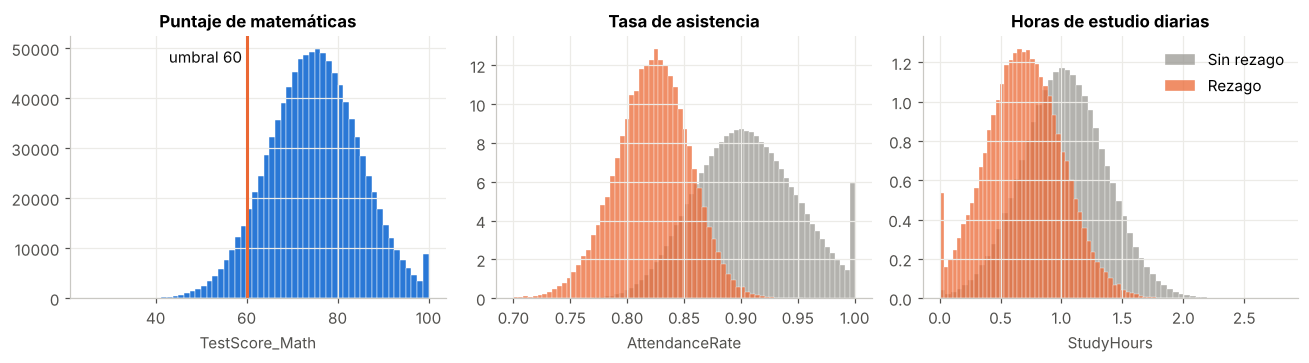

In [7]:
fig, ax = plt.subplots(1, 3, figsize=(12, 3.4))
ax[0].hist(train_raw.TestScore_Math, bins=60, color=AZUL, edgecolor='white', linewidth=0.3)
ax[0].axvline(60, color=NARANJO, lw=2); ax[0].text(59, ax[0].get_ylim()[1]*0.9, 'umbral 60', color=TINTA, ha='right')
ax[0].set_title('Puntaje de matemáticas'); ax[0].set_xlabel('TestScore_Math')
for a, col, lab in [(ax[1], 'AttendanceRate', 'Tasa de asistencia'), (ax[2], 'StudyHours', 'Horas de estudio diarias')]:
    for y, c, n in [(0, GRIS, 'Sin rezago'), (1, NARANJO, 'Rezago')]:
        a.hist(train_raw.loc[train_raw.rezago==y, col], bins=60, density=True, alpha=0.75, color=c, label=n, edgecolor='white', linewidth=0.3)
    a.set_title(lab); a.set_xlabel(col)
ax[2].legend(frameon=False)
plt.tight_layout(); plt.savefig(f'{FIG}/fig_eda_distribuciones.png', bbox_inches='tight'); plt.show()

### 1.2 Correlaciones y detección temprana de proxies (WBS 1.3.2)

Correlación con TestScore_Math:
AttendanceRate       0.815
TestScore_Reading    0.700
TestScore_Science    0.700
GPA                  0.684
StudyHours           0.457
GoOut                0.001
ParentSupport        0.001
Extracurricular      0.001
FreeTime             0.000
Age                  0.000
Romantic            -0.000
Grade               -0.000
PartTimeJob         -0.000
InternetAccess      -0.001
SES_Quartile        -0.002


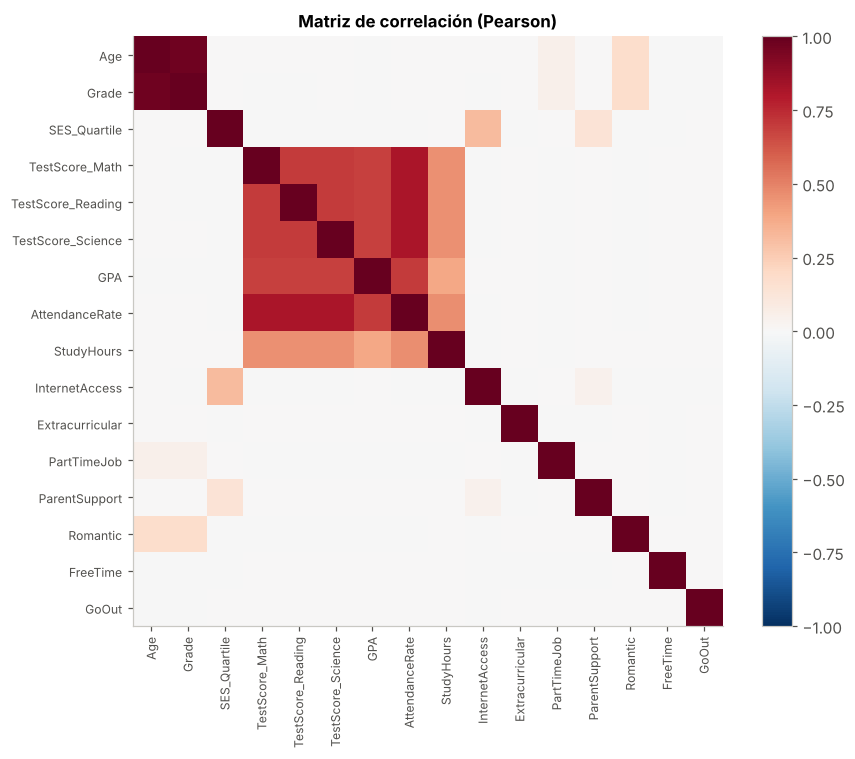

In [8]:
num = train_raw.select_dtypes('number').drop(columns=['rezago'])
corr = num.corr()
print('Correlación con TestScore_Math:'); print(corr['TestScore_Math'].drop('TestScore_Math').sort_values(ascending=False).round(3).to_string())
fig, ax = plt.subplots(figsize=(8.5, 7))
im = ax.imshow(corr, cmap='RdBu_r', vmin=-1, vmax=1)
ax.set_xticks(range(len(corr))); ax.set_xticklabels(corr.columns, rotation=90, fontsize=8)
ax.set_yticks(range(len(corr))); ax.set_yticklabels(corr.columns, fontsize=8); ax.grid(False)
plt.colorbar(im, fraction=0.04); ax.set_title('Matriz de correlación (Pearson)')
plt.tight_layout(); plt.savefig(f'{FIG}/fig_eda_correlacion.png', bbox_inches='tight'); plt.show()

In [9]:
# ¿Qué variables candidatas funcionan como proxy del nivel socioeconómico (SES)?
cand = ['InternetAccess', 'ParentSupport', 'PartTimeJob', 'Extracurricular', 'AttendanceRate', 'StudyHours']
proxy = train_raw[cand + ['SES_Quartile']].corr()['SES_Quartile'].drop('SES_Quartile').round(3)
print('Correlación con SES_Quartile:'); print(proxy.to_string())
# Asociación de atributos protegidos con el rezago (tasa por grupo)
for g in ['Gender', 'Race', 'SES_Quartile', 'ParentalEducation']:
    print(g, train_raw.groupby(g).rezago.mean().mul(100).round(2).to_dict())

Correlación con SES_Quartile:
InternetAccess     0.314
ParentSupport      0.140
PartTimeJob        0.001
Extracurricular   -0.001
AttendanceRate    -0.001
StudyHours         0.000
Gender {'Female': 6.7, 'Male': 6.7}
Race {'Asian': 6.77, 'Black': 6.76, 'Hispanic': 6.71, 'Other': 6.55, 'Two-or-more': 6.72, 'White': 6.67}
SES_Quartile {1: 6.63, 2: 6.75, 3: 6.68, 4: 6.75}


ParentalEducation {'<HS': 6.72, 'Bachelors+': 6.71, 'HS': 6.67, 'SomeCollege': 6.72}


### 1.3 Representatividad y diferencias de rendimiento por subgrupo

In [10]:
sub = {}
filas_sg = []
for g in ['Gender', 'Race', 'SES_Quartile', 'ParentalEducation', 'Locale', 'SchoolType']:
    t = train_raw.groupby(g).agg(n=('rezago', 'size'), rez=('rezago', 'mean'), math=('TestScore_Math', 'mean'))
    t['pct'] = t.n / len(train_raw) * 100
    sub[g] = t.round(4).reset_index().to_dict('records')
    filas_sg.append({'Atributo': g, 'Grupos': len(t), 'Grupo más pequeño': f"{t.n.idxmin()} ({t.n.min():,} · {t.pct.min():.1f} %)",
                     'Tasa de rezago mín–máx (%)': f"{t.rez.min()*100:.1f} – {t.rez.max()*100:.1f}",
                     'Puntaje medio mín–máx': f"{t.math.min():.1f} – {t.math.max():.1f}"})
json.dump(sub, open(f'{OUT}/subgrupos_eda.json', 'w'), ensure_ascii=False, indent=1, default=float)
pd.DataFrame(filas_sg).set_index('Atributo')

,Grupos,Grupo más pequeño,Tasa de rezago mín–máx (%),Puntaje medio mín–máx
Atributo,,,,
Gender,2,"Male (489,912 · 49.0 %)",6.7 – 6.7,75.0 – 75.0
Race,6,"Other (19,595 · 2.0 %)",6.5 – 6.8,74.9 – 75.1
SES_Quartile,4,"4 (249,606 · 25.0 %)",6.6 – 6.8,74.9 – 75.0
ParentalEducation,4,"<HS (186,843 · 18.7 %)",6.7 – 6.7,75.0 – 75.0
Locale,4,"Town (109,918 · 11.0 %)",6.6 – 6.8,74.9 – 75.0
SchoolType,2,"Private (154,493 · 15.5 %)",6.7 – 6.7,74.9 – 75.0


**Decisiones derivadas del EDA**
* `AttendanceRate` (r = 0,82) y `StudyHours` (r = 0,46) son los predictores más fuertes y además **modificables**, en línea con la necesidad N3.
* `InternetAccess` (r = 0,31 con SES) y `ParentSupport` (r = 0,14) actúan como **proxies socioeconómicos** y no aportan señal sobre el rezago → se excluyen (RNF-03, C4).
* La tasa de rezago es prácticamente igual entre géneros, etnias, cuartiles SES y educación parental (~6,7 %), lo que reduce el riesgo de sesgo histórico, aunque igual se audita el error del modelo por subgrupo (sección 4.3).

**Limitación de validez externa.** Estos patrones indican que el conjunto del caso es **sintético**: las variables demográficas tienen correlación prácticamente nula con el puntaje (|r| < 0,01, incluida SES) y el rezago es plano entre subgrupos. En un liceo chileno real el nivel socioeconómico, la asistencia y el rendimiento sí se relacionan, por lo que **la equidad medida aquí no se traslada automáticamente**: debe re-auditarse con los datos del establecimiento antes del Go. Además, 12.º grado tiene el doble de registros que los otros cursos (agrupa las edades 17 y 18), lo que duplica sus alertas en el resumen por curso.

## 2. Preparación de los datos (WBS 1.3.3–1.3.5 · E4 · H2)
ETL con: (a) identificador sustituto y **seudonimización SHA-256 con sal** (RF-01, RNF-02); (b) separación de los atributos protegidos en una **tabla de auditoría** aparte (RF-07); (c) **poda** de variables sensibles, intrusivas, proxies, redundantes y con riesgo de fuga; (d) prueba automática de la *Definition of Done* ética.

In [11]:
SAL = os.environ.get('SATMAT_SALT', 'sal-demo-cambiar-en-produccion')   # en producción: AWS Secrets Manager

COL_ID = 'StudentID'   # en producción: RUN o ID institucional del estudiante

def hash_id(df, prefijo):
    # Con ID institucional el hash es estable entre lotes (trazabilidad de RF-05). Los datos del caso no traen ID,
    # así que se usa la posición de la fila: solo sirve para esta demostración, porque cambia si cambia el orden.
    if COL_ID in df.columns:
        return [hashlib.sha256(f'{SAL}|{v}'.encode()).hexdigest()[:16] for v in df[COL_ID].astype(str)]
    return [hashlib.sha256(f'{SAL}|{prefijo}-{i:07d}'.encode()).hexdigest()[:16] for i in range(len(df))]

PROTEGIDOS   = ['Gender', 'Race', 'SES_Quartile', 'ParentalEducation']          # auditoría, nunca predictores
INTRUSIVAS   = ['Romantic', 'GoOut', 'FreeTime']                                # no curriculares
PROXIES      = ['InternetAccess', 'ParentSupport']                              # correlacionadas con SES
REDUNDANTES  = ['Age']                                                          # = Grade
FUGA         = ['TestScore_Math', 'GPA']                                        # define la etiqueta / la contiene
CONTEXTO     = ['Grade', 'SchoolType', 'Locale']                                # filtros del tablero y auditoría
PREDICTORES  = ['AttendanceRate', 'StudyHours', 'PartTimeJob', 'Extracurricular']
PROHIBIDAS   = set(PROTEGIDOS + INTRUSIVAS + PROXIES + FUGA)

def etl(df, prefijo):
    # Solo exige contexto y predictores: en inferencia no llegan la etiqueta, el GPA ni los atributos protegidos.
    t = time.time()
    faltan = [c for c in CONTEXTO + PREDICTORES if c not in df.columns]
    if faltan: raise ValueError(f'Faltan columnas obligatorias: {faltan}')
    df = df.copy()
    df.insert(0, 'hash_id', hash_id(df, prefijo))
    aud_cols = [c for c in PROTEGIDOS if c in df.columns]
    auditoria = df[['hash_id'] + aud_cols + CONTEXTO]                      # tabla separada, acceso restringido
    extra = [c for c in ['TestScore_Reading', 'TestScore_Science', 'GPA', 'rezago'] if c in df.columns]
    modelado  = df[['hash_id'] + CONTEXTO + PREDICTORES + extra]
    return modelado, auditoria, time.time() - t

train, aud_train, t_tr = etl(train_raw, 'TR')
test,  aud_test,  t_te = etl(test_raw,  'TE')
print(f'ETL entrenamiento: {t_tr:.1f} s | prueba: {t_te:.1f} s')
print('Columnas tabla de modelado:', list(train.columns))
print('Columnas tabla de auditoría:', list(aud_train.columns))
train.head(3)

ETL entrenamiento: 0.9 s | prueba: 0.9 s
Columnas tabla de modelado: ['hash_id', 'Grade', 'SchoolType', 'Locale', 'AttendanceRate', 'StudyHours', 'PartTimeJob', 'Extracurricular', 'TestScore_Reading', 'TestScore_Science', 'GPA', 'rezago']
Columnas tabla de auditoría: ['hash_id', 'Gender', 'Race', 'SES_Quartile', 'ParentalEducation', 'Grade', 'SchoolType', 'Locale']


,hash_id,Grade,SchoolType,Locale,AttendanceRate,StudyHours,PartTimeJob,Extracurricular,TestScore_Reading,TestScore_Science,GPA,rezago
0,e3198a271fa1b5fd,9,Public,City,0.964022,1.409700,0,1,88.390291,79.100697,3.509322,0
1,94bd4c8dcc4dbc38,12,Public,Rural,0.882988,1.112296,0,0,73.471428,89.012766,3.118458,0
2,e6dc342714be2f92,12,Public,Suburban,0.864401,1.214927,1,1,76.085029,85.131595,3.640436,0


In [12]:
# Prueba automática de la Definition of Done ética: ninguna variable prohibida entre los predictores
def test_sin_variables_prohibidas(features):
    usadas = PROHIBIDAS.intersection(features)
    assert not usadas, f'Variables prohibidas en el modelo: {usadas}'
    return 'OK — sin atributos protegidos, proxies, intrusivas ni fugas'

print(test_sin_variables_prohibidas(PREDICTORES))
try:
    test_sin_variables_prohibidas(PREDICTORES + ['Gender'])
except AssertionError as e:
    print('Control funciona → detecta:', e)

OK — sin atributos protegidos, proxies, intrusivas ni fugas
Control funciona → detecta: Variables prohibidas en el modelo: {'Gender'}


In [13]:
# Diccionario de datos (E4)
dicc = pd.DataFrame([
  ('hash_id','ID seudonimizado (SHA-256 con sal, 16 hex)','Identificador','Modelado y auditoría'),
  ('Grade','Curso (9.º–12.º)','Contexto','Filtro tablero / subgrupo auditoría'),
  ('SchoolType','Tipo de establecimiento','Contexto','Subgrupo auditoría'),
  ('Locale','Zona (City, Suburban, Town, Rural)','Contexto','Subgrupo auditoría'),
  ('AttendanceRate','Tasa de asistencia (0,70–1,00)','Predictor accionable','Modelo'),
  ('StudyHours','Horas de estudio diarias','Predictor accionable','Modelo'),
  ('PartTimeJob','Trabajo a tiempo parcial (0/1)','Predictor contextual','Modelo'),
  ('Extracurricular','Actividad extracurricular (0/1)','Predictor contextual','Modelo'),
  ('TestScore_Reading/Science','Puntajes de otras asignaturas','Excluida (simultánea, aporte marginal)','Solo análisis de sensibilidad'),
  ('GPA','Promedio general','Excluida (contiene la nota de matemáticas → fuga)','Solo análisis de sensibilidad'),
  ('rezago','1 si TestScore_Math < 60','Objetivo','Etiqueta'),
  ('Gender, Race, SES_Quartile, ParentalEducation','Atributos protegidos','Excluidos como predictores','Tabla de auditoría (acceso restringido)'),
  ('InternetAccess, ParentSupport','Proxies de SES','Excluidas','—'),
  ('Romantic, GoOut, FreeTime','Vida privada','Excluidas (intrusivas)','—'),
  ('Age','Edad','Excluida (redundante con Grade)','—'),
], columns=['Variable','Descripción','Tratamiento','Uso'])
dicc.to_csv(f'{OUT}/diccionario_datos.csv', index=False, encoding='utf-8-sig')
dicc

,Variable,Descripción,Tratamiento,Uso
0,hash_id,"ID seudonimizado (SHA-256 con sal, 16 hex)",Identificador,Modelado y auditoría
1,Grade,Curso (9.º–12.º),Contexto,Filtro tablero / subgrupo auditoría
2,SchoolType,Tipo de establecimiento,Contexto,Subgrupo auditoría
3,Locale,"Zona (City, Suburban, Town, Rural)",Contexto,Subgrupo auditoría
4,AttendanceRate,"Tasa de asistencia (0,70–1,00)",Predictor accionable,Modelo
5,StudyHours,Horas de estudio diarias,Predictor accionable,Modelo
6,PartTimeJob,Trabajo a tiempo parcial (0/1),Predictor contextual,Modelo
7,Extracurricular,Actividad extracurricular (0/1),Predictor contextual,Modelo
8,TestScore_Reading/Science,Puntajes de otras asignaturas,"Excluida (simultánea, aporte marginal)",Solo análisis de sensibilidad
9,GPA,Promedio general,Excluida (contiene la nota de matemáticas → fuga),Solo análisis de sensibilidad


## 3. Modelado (WBS 1.4.1–1.4.3 · E5)
Validación cruzada estratificada de 5 pliegues (por clase y curso) sobre el conjunto de entrenamiento. Se comparan el **baseline de regresión logística**, **Random Forest** y **XGBoost**, como define el plan.

In [14]:
X, y = train[PREDICTORES], train['rezago']
estrato = train['rezago'].astype(str) + '_' + train['Grade'].astype(str)
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
folds = list(skf.split(X, estrato))

modelos = {
  'Regresión logística (baseline)': make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
  'Random Forest':  RandomForestClassifier(n_estimators=150, max_depth=10, min_samples_leaf=50, n_jobs=-1,
                                           class_weight='balanced_subsample', max_samples=0.25, random_state=SEED),
  'XGBoost':        xgb.XGBClassifier(n_estimators=300, max_depth=4, learning_rate=0.1, subsample=0.8,
                                      scale_pos_weight=(1-prev)/prev, tree_method='hist', n_jobs=-1, random_state=SEED),
}

def umbral_recall(y_true, p, objetivo=0.80):
    pr, rc, th = precision_recall_curve(y_true, p)
    ok = rc[:-1] >= objetivo
    i = np.argmax(np.where(ok, pr[:-1], -1))
    return th[i]

def metricas(y_true, p, u):
    yhat = (p >= u).astype(int)
    return {'AUC': roc_auc_score(y_true, p), 'Recall': recall_score(y_true, yhat),
            'Precisión': precision_score(y_true, yhat), 'F1': f1_score(y_true, yhat)}

oof, filas = {}, []
for nombre, m in modelos.items():
    t = time.time()
    oof[nombre] = cross_val_predict(m, X, y, cv=folds, method='predict_proba', n_jobs=1)[:, 1]
    u = umbral_recall(y, oof[nombre])
    filas.append({'Modelo': nombre, **metricas(y, oof[nombre], u), 'Umbral': u, 'Tiempo CV (s)': time.time()-t})
cv_res = pd.DataFrame(filas).set_index('Modelo').round(3)
cv_res.to_csv(f'{OUT}/resultados_cv.csv', encoding='utf-8-sig')
cv_res

,AUC,Recall,Precisión,F1,Umbral,Tiempo CV (s)
Modelo,,,,,,
Regresión logística (baseline),0.939,0.8,0.361,0.497,0.114,2.475
Random Forest,0.938,0.8,0.359,0.496,0.648,144.352
XGBoost,0.938,0.8,0.361,0.497,0.674,33.158


Los tres modelos alcanzan prácticamente el mismo desempeño (AUC ≈ 0,94). La relación entre asistencia, horas de estudio y rezago es casi lineal, de modo que los modelos de árboles no agregan capacidad predictiva. **Se selecciona la regresión logística**: iguala a XGBoost, es más rápida, sus coeficientes son interpretables y su explicación SHAP es exacta (Hosmer et al., 2013). Nota: Random Forest y XGBoost se entrenaron con reponderación de clases y la logística sin ella; eso cambia la escala de las probabilidades, pero no el AUC ni la comparación en el mismo punto de operación (recall 0,80), que es lo que se usa para decidir.

**¿Fueron suficientes las etapas previas?** En lo técnico, sí: el ETL entregó datos sin nulos ni duplicados y la poda de variables dejó predictores con señal suficiente (AUC ≈ 0,94). En lo planificado, no del todo: el plan suponía 107.350 registros, un identificador y dos cohortes, y nada de eso estaba en los datos; además, la meta de precisión ≥ 0,50 no consideró la prevalencia real del 6,7 %. Esos desvíos se corrigen en la evaluación (alerta en dos niveles) y se registran en el control del proyecto.

### 3.1 Análisis de sensibilidad: ¿vale la pena incluir variables con riesgo de fuga?

In [15]:
conjuntos = {'A · Accionables (seleccionado)': PREDICTORES,
             'B · A + puntajes Lectura/Ciencias': PREDICTORES + ['TestScore_Reading', 'TestScore_Science'],
             'C · B + GPA': PREDICTORES + ['TestScore_Reading', 'TestScore_Science', 'GPA']}
filas = []
for nombre, F in conjuntos.items():
    p = cross_val_predict(modelos['Regresión logística (baseline)'], train[F], y, cv=folds, method='predict_proba')[:, 1]
    filas.append({'Conjunto': nombre, **metricas(y, p, umbral_recall(y, p))})
sens = pd.DataFrame(filas).set_index('Conjunto').round(3)
sens.to_csv(f'{OUT}/sensibilidad_variables.csv', encoding='utf-8-sig')
sens

,AUC,Recall,Precisión,F1
Conjunto,,,,
A · Accionables (seleccionado),0.939,0.8,0.361,0.497
B · A + puntajes Lectura/Ciencias,0.940,0.8,0.364,0.500
C · B + GPA,0.944,0.8,0.384,0.519


Agregar puntajes de otras asignaturas y el GPA sube la precisión solo 1–2 puntos, a cambio de usar información simultánea a la nota de matemáticas (el GPA la contiene). Se mantiene el **conjunto A**: evita la fuga de información (RD-02) y conserva alertas explicadas por factores modificables (N3).

## 4. Evaluación (WBS 1.5.1–1.5.2 · E6 · H3)
### 4.1 Umbrales de decisión (fijados con predicciones fuera de pliegue, nunca con el conjunto de prueba)
Con una prevalencia del 6,7 %, ningún modelo logra a la vez recall ≥ 0,80 y precisión ≥ 0,50 con un solo umbral. **Acción correctiva AC-03**: alerta en dos niveles.
* **Alto**: umbral que logra precisión ≥ 0,50 (derivación prioritaria a tutoría).
* **Medio**: umbral que logra recall ≥ 0,80 (seguimiento preventivo del docente).
* **Bajo**: resto.

In [16]:
p_oof = oof['Regresión logística (baseline)']
U_MEDIO = umbral_recall(y, p_oof, 0.80)
pr, rc, th = precision_recall_curve(y, p_oof)
U_ALTO = th[np.argmax(pr[:-1] >= 0.50)]
print(f'Umbral MEDIO (recall ≥ 0,80): {U_MEDIO:.3f}  |  Umbral ALTO (precisión ≥ 0,50): {U_ALTO:.3f}')

final = modelos['Regresión logística (baseline)'].fit(X, y)
p_test = final.predict_proba(test[PREDICTORES])[:, 1]
yt = test['rezago']

def nivel(p): return np.where(p >= U_ALTO, 'Alto', np.where(p >= U_MEDIO, 'Medio', 'Bajo'))
test = test.assign(prob=p_test, nivel=nivel(p_test))

res = []
for etiqueta, u in [('Alto', U_ALTO), ('Alto + Medio', U_MEDIO)]:
    yhat = (p_test >= u).astype(int)
    res.append({'Alerta': etiqueta, 'Umbral': u, 'Estudiantes alertados': yhat.sum(), '% alertado': yhat.mean()*100,
                'Recall': recall_score(yt, yhat), 'Precisión': precision_score(yt, yhat), 'F1': f1_score(yt, yhat)})
eval_test = pd.DataFrame(res).set_index('Alerta').round(3)
auc_test = roc_auc_score(yt, p_test)
print(f'AUC en prueba independiente: {auc_test:.3f}')
eval_test.to_csv(f'{OUT}/evaluacion_test.csv', encoding='utf-8-sig')
eval_test

Umbral MEDIO (recall ≥ 0,80): 0.114  |  Umbral ALTO (precisión ≥ 0,50): 0.250


AUC en prueba independiente: 0.939


,Umbral,Estudiantes alertados,% alertado,Recall,Precisión,F1
Alerta,,,,,,
Alto,0.250,81970,8.197,0.613,0.50,0.551
Alto + Medio,0.114,148564,14.856,0.800,0.36,0.496


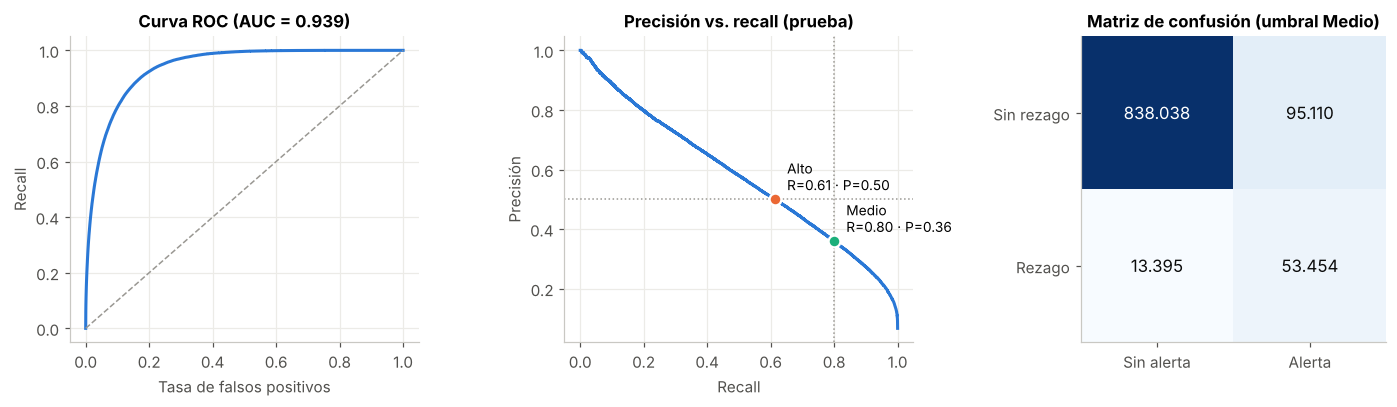

In [17]:
fig, ax = plt.subplots(1, 3, figsize=(13, 3.8))
fpr, tpr, _ = roc_curve(yt, p_test)
ax[0].plot(fpr, tpr, color=AZUL, lw=2); ax[0].plot([0,1],[0,1], color=GRIS, lw=1, ls='--')
ax[0].set_title(f'Curva ROC (AUC = {auc_test:.3f})'); ax[0].set_xlabel('Tasa de falsos positivos'); ax[0].set_ylabel('Recall')
pr_t, rc_t, _ = precision_recall_curve(yt, p_test)
ax[1].plot(rc_t, pr_t, color=AZUL, lw=2)
for etiqueta, u, c in [('Alto', U_ALTO, NARANJO), ('Medio', U_MEDIO, AQUA)]:
    yh = p_test >= u; r_, p_ = recall_score(yt, yh), precision_score(yt, yh)
    ax[1].scatter(r_, p_, s=60, color=c, zorder=3, edgecolor='white', linewidth=1.5)
    ax[1].annotate(f'{etiqueta}\nR={r_:.2f} · P={p_:.2f}', (r_, p_), xytext=(8, 6), textcoords='offset points', fontsize=9)
ax[1].axhline(0.5, color=GRIS, lw=1, ls=':'); ax[1].axvline(0.8, color=GRIS, lw=1, ls=':')
ax[1].set_title('Precisión vs. recall (prueba)'); ax[1].set_xlabel('Recall'); ax[1].set_ylabel('Precisión')
cm = confusion_matrix(yt, (p_test >= U_MEDIO).astype(int))
ax[2].imshow(cm, cmap='Blues'); ax[2].grid(False)
for (i, j), v in np.ndenumerate(cm):
    ax[2].text(j, i, f'{v:,}'.replace(',', '.'), ha='center', va='center', color='white' if v > cm.max()/2 else TINTA, fontsize=11)
ax[2].set_xticks([0,1]); ax[2].set_xticklabels(['Sin alerta','Alerta']); ax[2].set_yticks([0,1]); ax[2].set_yticklabels(['Sin rezago','Rezago'])
ax[2].set_title('Matriz de confusión (umbral Medio)')
plt.tight_layout(); plt.savefig(f'{FIG}/fig_eval_curvas.png', bbox_inches='tight'); plt.show()

### 4.2 Distribución de la nómina por nivel de riesgo

In [18]:
dist = test.groupby('nivel').agg(estudiantes=('prob','size'), tasa_rezago_real=('rezago','mean')).reindex(['Alto','Medio','Bajo'])
dist['% del total'] = dist.estudiantes / len(test) * 100
dist.round(3)

,estudiantes,tasa_rezago_real,% del total
nivel,,,
Alto,81970,0.500,8.197
Medio,66594,0.187,6.659
Bajo,851433,0.016,85.144


### 4.3 Auditoría de equidad (RF-07 · RNF-03)
Brecha de tasa de falsos negativos (FNR) y de falsos positivos (FPR) entre subgrupos, usando la tabla de auditoría separada. Criterio: brecha FNR ≤ 5 pp (igualdad de oportunidades; Hardt et al., 2016). Se audita en los **dos umbrales**: Medio (seguimiento preventivo) y Alto, que es el que asigna el recurso escaso (tutoría prioritaria). No se auditan grupos interseccionales (p. ej., etnia × SES): queda como mejora para el piloto real.

In [19]:
aud = aud_test[['hash_id'] + PROTEGIDOS].merge(test[['hash_id','Grade','SchoolType','Locale','rezago','prob']], on='hash_id')

def tasas(g):
    pos, neg = g[g.rezago==1], g[g.rezago==0]
    return pd.Series({'n': len(g), 'FNR': 1 - pos.alerta.mean(), 'FPR': neg.alerta.mean()})

def auditar(a, umbral, atributos=PROTEGIDOS + ['Grade', 'SchoolType', 'Locale']):
    a = a.assign(alerta=(a.prob >= umbral).astype(int))
    filas = []
    for attr in [x for x in atributos if x in a.columns]:
        t = a.groupby(attr).apply(tasas)
        filas.append({'Atributo': attr, 'Grupos': len(t),
                      'Brecha FNR (pp)': (t.FNR.max()-t.FNR.min())*100, 'Brecha FPR (pp)': (t.FPR.max()-t.FPR.min())*100,
                      'Cumple RNF-03': '✓' if (t.FNR.max()-t.FNR.min())*100 <= 5 else '✗'})
    return pd.DataFrame(filas).set_index('Atributo').round(2)

aud['alerta'] = (aud.prob >= U_MEDIO).astype(int)
equidad = auditar(aud, U_MEDIO)             # umbral Medio: seguimiento preventivo (criterio RNF-03 del plan)
equidad_alto = auditar(aud, U_ALTO)         # umbral Alto: asigna el recurso escaso (tutoría prioritaria)
equidad.to_csv(f'{OUT}/auditoria_equidad.csv', encoding='utf-8-sig')
equidad_alto.to_csv(f'{OUT}/auditoria_equidad_alto.csv', encoding='utf-8-sig')
display(equidad)
print('Umbral Alto (derivación prioritaria):')
equidad_alto

,Grupos,Brecha FNR (pp),Brecha FPR (pp),Cumple RNF-03
Atributo,,,,
Gender,2,0.32,0.07,✓
Race,6,1.40,0.39,✓
SES_Quartile,4,0.42,0.06,✓
ParentalEducation,4,0.67,0.07,✓
Grade,4,0.72,0.11,✓
SchoolType,2,0.30,0.11,✓
Locale,4,1.42,0.11,✓


Umbral Alto (derivación prioritaria):


,Grupos,Brecha FNR (pp),Brecha FPR (pp),Cumple RNF-03
Atributo,,,,
Gender,2,0.08,0.09,✓
Race,6,1.32,0.18,✓
SES_Quartile,4,0.41,0.08,✓
ParentalEducation,4,0.46,0.10,✓
Grade,4,0.67,0.03,✓
SchoolType,2,1.05,0.07,✓
Locale,4,1.21,0.08,✓


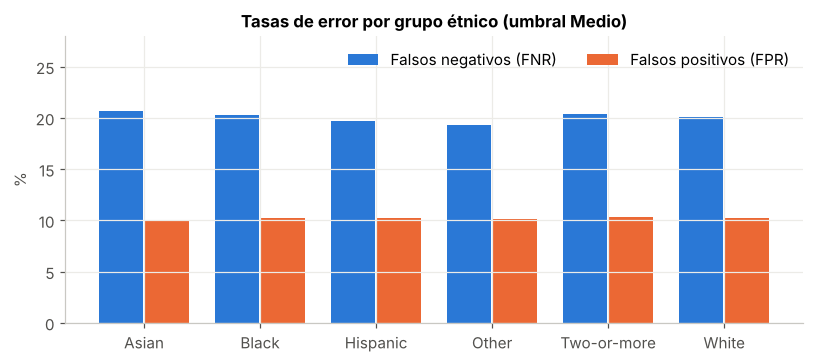

In [20]:
t_race = aud.groupby('Race').apply(tasas)
fig, ax = plt.subplots(figsize=(7.5, 3.4))
xs = np.arange(len(t_race)); w = 0.38
ax.bar(xs - w/2 - 0.01, t_race.FNR*100, w, color=AZUL, label='Falsos negativos (FNR)')
ax.bar(xs + w/2 + 0.01, t_race.FPR*100, w, color=NARANJO, label='Falsos positivos (FPR)')
ax.set_xticks(xs); ax.set_xticklabels(t_race.index); ax.set_ylabel('%')
ax.set_title('Tasas de error por grupo étnico (umbral Medio)'); ax.legend(frameon=False, ncol=2, loc='upper right')
ax.set_ylim(0, max(t_race.FNR.max(), t_race.FPR.max())*100*1.35)
plt.tight_layout(); plt.savefig(f'{FIG}/fig_equidad_race.png', bbox_inches='tight'); plt.show()

## 5. Explicabilidad SHAP (WBS 1.4.4 · RF-04)
Para la regresión logística los valores SHAP son exactos (`LinearExplainer`) y se expresan en log-odds de rezago.

Importancia global (|SHAP| medio):
AttendanceRate     2.011
StudyHours         0.254
Extracurricular    0.004
PartTimeJob        0.000
Coeficientes (variables estandarizadas): {'AttendanceRate': np.float64(-2.507), 'StudyHours': np.float64(-0.318), 'PartTimeJob': np.float64(-0.0), 'Extracurricular': np.float64(-0.004)}


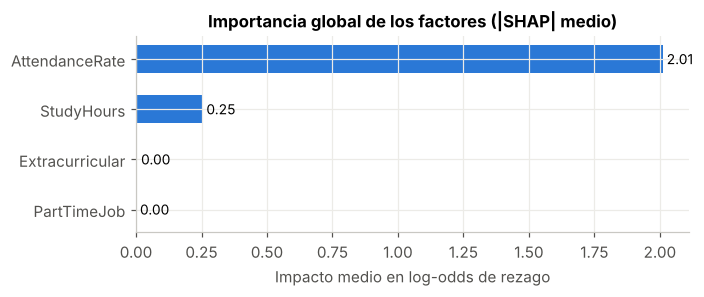

In [21]:
scaler, lr = final.named_steps['standardscaler'], final.named_steps['logisticregression']
fondo = scaler.transform(X.sample(5000, random_state=SEED))
explainer = shap.LinearExplainer(lr, shap.maskers.Independent(fondo, max_samples=5000))
muestra = test.sample(20000, random_state=SEED)
sv = explainer(scaler.transform(muestra[PREDICTORES]))
sv.feature_names = PREDICTORES
imp = pd.Series(np.abs(sv.values).mean(0), index=PREDICTORES).sort_values()
print('Importancia global (|SHAP| medio):'); print(imp[::-1].round(3).to_string())
print('Coeficientes (variables estandarizadas):', dict(zip(PREDICTORES, lr.coef_[0].round(3))))
fig, ax = plt.subplots(figsize=(6.5, 2.8))
ax.barh(imp.index, imp.values, color=AZUL, height=0.55)
for i, v in enumerate(imp.values): ax.text(v, i, f' {v:.2f}', va='center', fontsize=9)
ax.set_title('Importancia global de los factores (|SHAP| medio)'); ax.set_xlabel('Impacto medio en log-odds de rezago')
plt.tight_layout(); plt.savefig(f'{FIG}/fig_shap_global.png', bbox_inches='tight'); plt.show()

In [22]:
NOMBRES = {'AttendanceRate': 'Asistencia', 'StudyHours': 'Horas de estudio', 'PartTimeJob': 'Trabajo part-time',
           'Extracurricular': 'Actividad extracurricular'}
MEDIAS = X.mean()

def texto_factor(f, valor, contrib):
    sentido = 'aumenta' if contrib > 0 else 'reduce'
    if f == 'AttendanceRate':   d = f'{valor:.0%} (promedio {MEDIAS[f]:.0%})'
    elif f == 'StudyHours':     d = f'{valor:.1f} h/día (promedio {MEDIAS[f]:.1f})'.replace('.', ',')
    else:                       d = 'sí' if valor == 1 else 'no'
    return f'{NOMBRES[f]}: {d} → {sentido} el riesgo'

MIN_CONTRIB = 0.05   # factores con efecto despreciable (< 0,05 log-odds) no se muestran en la ficha
# RF-04 se implementa como «hasta 3 factores relevantes»: en estos datos solo asistencia y horas de estudio superan el
# umbral, porque trabajo part-time y actividades extracurriculares casi no aportan al modelo (ver importancia global).

def ficha(fila_shap, fila_x, k=3):
    orden = [j for j in np.argsort(-np.abs(fila_shap))[:k] if abs(fila_shap[j]) >= MIN_CONTRIB]
    return [texto_factor(PREDICTORES[j], fila_x[PREDICTORES[j]], fila_shap[j]) for j in orden]

ejemplo = muestra.assign(_i=range(len(muestra))).query("nivel == 'Alto'").iloc[0]
print('FICHA DIAGNÓSTICA (ejemplo)')
print(f"Estudiante {ejemplo.hash_id} · {int(ejemplo.Grade)}.º · probabilidad de rezago {ejemplo.prob:.0%} · nivel {ejemplo.nivel}")
for f in ficha(sv.values[int(ejemplo._i)], ejemplo): print('  •', f)
print('Acción sugerida: revisar con Orientación; validar o descartar la alerta con motivo (RF-05).')

FICHA DIAGNÓSTICA (ejemplo)
Estudiante ed4873c87d6f20da · 12.º · probabilidad de rezago 54% · nivel Alto
  • Asistencia: 81% (promedio 90%) → aumenta el riesgo
  • Horas de estudio: 0,8 h/día (promedio 1,0) → aumenta el riesgo
Acción sugerida: revisar con Orientación; validar o descartar la alerta con motivo (RF-05).


## 6. Despliegue por lotes: nómina de alertas para el tablero (WBS 1.6.2–1.6.3 · E7)
Función de puntuación por lote que replica lo que ejecutará AWS Lambda: valida la entrada, aplica el ETL de inferencia (solo contexto y predictores), puntúa, genera la ficha con hasta 3 factores relevantes y exporta la nómina para Power BI. Se mide el tiempo sobre el millón de registros de prueba (RNF-06: < 15 min).

In [23]:
def validar_entrada(df):
    faltan = [c for c in PREDICTORES if c not in df.columns]
    if faltan: raise ValueError(f'Faltan predictores: {faltan}')
    errores = []
    nulos = df[PREDICTORES].isna().sum()
    if nulos.any(): errores.append('Valores nulos en: ' + ', '.join(f'{k} ({v})' for k, v in nulos[nulos > 0].items()))
    if not df['AttendanceRate'].dropna().between(0, 1).all(): errores.append('AttendanceRate debe estar entre 0 y 1')
    if not df['StudyHours'].dropna().between(0, 24).all(): errores.append('StudyHours debe estar entre 0 y 24')
    for c in ['PartTimeJob', 'Extracurricular']:
        if not df[c].dropna().isin([0, 1]).all(): errores.append(f'{c} debe ser 0 o 1')
    if errores: raise ValueError('; '.join(errores))
    return True

# El escalador se ajustó con los datos de entrenamiento: en la escala z la media de entrenamiento es 0.
# Por eso la contribución de cada factor es z × coeficiente, siempre contra el promedio de entrenamiento
# (la misma referencia que muestra el texto de la ficha), nunca contra la media del propio lote.
REF_Z = scaler.transform(X).mean(0)
joblib.dump({'modelo': final, 'predictores': PREDICTORES, 'u_alto': U_ALTO, 'u_medio': U_MEDIO,
             'medias_entrenamiento': MEDIAS.to_dict(), 'ref_z': REF_Z}, f'{OUT}/modelo_satmat.joblib')

def puntuar_lote(df_crudo, prefijo='LOTE'):
    t = time.time()
    validar_entrada(df_crudo)                                   # rechaza columnas faltantes, nulos y rangos inválidos
    mod, _, _ = etl(df_crudo, prefijo)                          # no exige etiqueta, GPA ni atributos protegidos
    test_sin_variables_prohibidas(PREDICTORES)
    p = final.predict_proba(mod[PREDICTORES])[:, 1]
    z = scaler.transform(mod[PREDICTORES]); contrib = (z - REF_Z) * lr.coef_[0]
    mod = mod.assign(prob=p.round(4), nivel=nivel(p))
    alerta = mod.nivel != 'Bajo'
    ca = contrib[alerta.values]
    top = np.argsort(-np.abs(ca), axis=1)[:, :3]
    sub = mod.loc[alerta].reset_index(drop=True)
    vals = sub[PREDICTORES].to_numpy()
    for k in range(3):
        sub[f'factor_{k+1}'] = [texto_factor(PREDICTORES[j], vals[i, j], ca[i, j]) if abs(ca[i, j]) >= MIN_CONTRIB else ''
                                for i, j in enumerate(top[:, k])]
    sub['validacion_orientacion'] = 'Pendiente'; sub['motivo'] = ''
    cols = ['hash_id', 'Grade', 'SchoolType', 'prob', 'nivel', 'factor_1', 'factor_2', 'factor_3', 'validacion_orientacion', 'motivo']
    return sub[cols].sort_values('prob', ascending=False), time.time() - t

# El lote de producción solo trae contexto y predictores (sin nota, GPA ni atributos protegidos)
lote_prod = test_raw[CONTEXTO + PREDICTORES]
nomina, segundos = puntuar_lote(lote_prod, 'TE')
print(f'Lote de {len(test_raw):,} registros procesado en {segundos:.1f} s ({segundos/60:.2f} min) → RNF-06 {"✓" if segundos < 900 else "✗"}'.replace(',', '.'))
print('Alertas generadas:', nomina.nivel.value_counts().to_dict())
cobertura = {f'factor_{k}': round(float((nomina[f'factor_{k}'] != '').mean() * 100), 1) for k in (1, 2, 3)}
print('% de alertas con cada factor en la ficha:', cobertura)
nomina.to_csv(f'{OUT}/nomina_alertas.csv', index=False, encoding='utf-8-sig')
nomina.head(5)

Lote de 999.997 registros procesado en 2.1 s (0.03 min) → RNF-06 ✓
Alertas generadas: {'Alto': 81970, 'Medio': 66594}
% de alertas con cada factor en la ficha: {'factor_1': 100.0, 'factor_2': 91.2, 'factor_3': 0.0}


,hash_id,Grade,SchoolType,prob,nivel,factor_1,factor_2,factor_3,validacion_orientacion,motivo
76957,75455c448062127b,12,Private,0.9985,Alto,Asistencia: 70% (promedio 90%) → aumenta el ri...,"Horas de estudio: 0,0 h/día (promedio 1,0) → a...",,Pendiente,
93236,3df6213bc8540adb,10,Public,0.9985,Alto,Asistencia: 70% (promedio 90%) → aumenta el ri...,"Horas de estudio: 0,0 h/día (promedio 1,0) → a...",,Pendiente,
677,cc489b4464b709f4,12,Public,0.9985,Alto,Asistencia: 70% (promedio 90%) → aumenta el ri...,"Horas de estudio: 0,0 h/día (promedio 1,0) → a...",,Pendiente,
92801,9286be5b7abe1e86,9,Public,0.9985,Alto,Asistencia: 70% (promedio 90%) → aumenta el ri...,"Horas de estudio: 0,0 h/día (promedio 1,0) → a...",,Pendiente,
139495,e03f1d21199bcfb4,10,Public,0.9984,Alto,Asistencia: 70% (promedio 90%) → aumenta el ri...,"Horas de estudio: 0,0 h/día (promedio 1,0) → a...",,Pendiente,


In [24]:
# Resumen semanal para Orientación (insumo del correo de Amazon SES, RF-06)
resumen = (nomina.groupby(['Grade', 'nivel']).size().unstack(fill_value=0)[['Alto', 'Medio']]
           .rename_axis(index='Curso', columns=None))
resumen['Total'] = resumen.sum(1)
resumen.to_csv(f'{OUT}/resumen_semanal_alertas.csv', encoding='utf-8-sig')
resumen

,Alto,Medio,Total
Curso,,,
9,16333,13402,29735
10,16420,13177,29597
11,16327,13397,29724
12,32890,26618,59508


## 7. Usar el modelo con datos nuevos: 5 predicciones
Se puntúan cinco **perfiles tipo** de estudiantes (no personas reales) para mostrar cómo el sistema traduce los datos en una alerta explicada. Antes de puntuar, `validar_entrada()` (definida en la sección 6 y usada también por `puntuar_lote()` y `alerta_curso()`) rechaza columnas faltantes, nulos y valores fuera de rango.

In [25]:
perfiles = pd.DataFrame([
    ('Asistencia alta y buen hábito de estudio', 0.97, 1.5, 0, 1),
    ('Estudiante promedio', 0.90, 1.0, 0, 1),
    ('Asistencia media, trabaja part-time', 0.86, 0.8, 1, 0),
    ('Asistencia baja, poco estudio', 0.82, 0.5, 0, 0),
    ('Ausentismo alto, casi sin estudio', 0.76, 0.3, 1, 0),
], columns=['Perfil'] + PREDICTORES)
validar_entrada(perfiles)
pp = final.predict_proba(perfiles[PREDICTORES])[:, 1]
zp = scaler.transform(perfiles[PREDICTORES]); cp = (zp - REF_Z) * lr.coef_[0]
pred5 = perfiles.assign(**{'Probabilidad de rezago': (pp * 100).round(1), 'Nivel': nivel(pp),
                           'Factores': ['; '.join(ficha(cp[i], perfiles.iloc[i])) or 'Sin factores relevantes' for i in range(len(perfiles))]})
pred5.to_csv(f'{OUT}/predicciones_perfiles.csv', index=False, encoding='utf-8-sig')
pred5[['Perfil', 'AttendanceRate', 'StudyHours', 'PartTimeJob', 'Probabilidad de rezago', 'Nivel', 'Factores']]

,Perfil,AttendanceRate,StudyHours,PartTimeJob,Probabilidad de rezago,Nivel,Factores
0,Asistencia alta y buen hábito de estudio,0.97,1.5,0,0.0,Bajo,Asistencia: 97% (promedio 90%) → reduce el rie...
1,Estudiante promedio,0.90,1.0,0,0.8,Bajo,Sin factores relevantes
2,"Asistencia media, trabaja part-time",0.86,0.8,1,6.9,Bajo,Asistencia: 86% (promedio 90%) → aumenta el ri...
3,"Asistencia baja, poco estudio",0.82,0.5,0,43.9,Alto,Asistencia: 82% (promedio 90%) → aumenta el ri...
4,"Ausentismo alto, casi sin estudio",0.76,0.3,1,95.5,Alto,Asistencia: 76% (promedio 90%) → aumenta el ri...


In [26]:
rechazo_rango = False
try:
    validar_entrada(pd.DataFrame([{'AttendanceRate': 1.4, 'StudyHours': 2, 'PartTimeJob': 0, 'Extracurricular': 1}]))
except ValueError as e:
    print('Entrada inválida rechazada →', e); rechazo_rango = True
rechazo_nulo = False
try:
    validar_entrada(pd.DataFrame([{'AttendanceRate': np.nan, 'StudyHours': 2, 'PartTimeJob': 0, 'Extracurricular': 1}]))
except ValueError as e:
    print('Entrada con nulos rechazada →', e); rechazo_nulo = True

Entrada inválida rechazada → AttendanceRate debe estar entre 0 y 1
Entrada con nulos rechazada → Valores nulos en: AttendanceRate (1)


## 8. Automatización propuesta e implementada
Tres funciones que cubren requerimientos y riesgos del plan, cada una probada con un caso positivo y uno negativo:
* **Alerta por curso (RF-06):** avisa a Orientación cuando la proporción de nivel Alto en un curso supera un umbral. Solo opera sobre grupos de 20 o más estudiantes (uso agregado).
* **Detección de deriva (riesgo de cambio de población):** compara un lote nuevo con los datos de entrenamiento (Kolmogorov-Smirnov para variables continuas y chi-cuadrado para las categóricas).
* **Reentrenamiento reproducible (RF-08):** reentrena con semilla fija, recalibra **los dos umbrales** (Medio y Alto) con predicciones fuera de pliegue, y solo promueve el modelo si en una partición de validación cumple **sin tolerancias** AUC ≥ 0,80, recall ≥ 0,80, precisión ≥ 0,50 en Alto y brecha de falsos negativos ≤ 5 pp (RNF-03). Para que el criterio estricto se cumpla pese a la variación muestral, los umbrales se calibran con un margen (recall objetivo 0,82 y precisión objetivo 0,52). Deja un registro con métricas y parámetros.

In [27]:
from scipy.stats import ks_2samp, chi2_contingency
UMBRAL_CURSO, MIN_GRUPO = 0.12, 20

def alerta_curso(lote, umbral=UMBRAL_CURSO, min_grupo=MIN_GRUPO):
    validar_entrada(lote[PREDICTORES])
    if len(lote) < min_grupo:
        raise ValueError(f'Grupo de {len(lote)} estudiantes: la alerta solo opera con {min_grupo} o más')
    p = final.predict_proba(lote[PREDICTORES])[:, 1]
    pct_alto = float((p >= U_ALTO).mean())
    return {'estudiantes': len(lote), 'pct_alto': round(pct_alto * 100, 1), 'umbral_pct': umbral * 100, 'alerta': pct_alto > umbral}

rng = np.random.default_rng(SEED)
curso_normal = test_raw.sample(40, random_state=1)
curso_riesgo = curso_normal.copy()
curso_riesgo['AttendanceRate'] = (curso_riesgo['AttendanceRate'] - 0.06).clip(0, 1)   # simula caída de asistencia de 6 pp
curso_riesgo['StudyHours'] = curso_riesgo['StudyHours'] * 0.7
res_alerta = {'Curso habitual (40 estudiantes)': alerta_curso(curso_normal),
              'Curso con caída de asistencia (simulado)': alerta_curso(curso_riesgo)}
try:
    alerta_curso(curso_normal.head(12)); rechazo_min = False
except ValueError as e:
    print('Grupo pequeño rechazado →', e); rechazo_min = True
pd.DataFrame(res_alerta).T

Grupo pequeño rechazado → Grupo de 12 estudiantes: la alerta solo opera con 20 o más


,estudiantes,pct_alto,umbral_pct,alerta
Curso habitual (40 estudiantes),40,7.5,12.0,False
Curso con caída de asistencia (simulado),40,50.0,12.0,True


In [28]:
REF = train_raw.sample(20000, random_state=SEED)

def detectar_deriva(lote, ref=REF, alfa=0.01, efecto=0.05):
    filas = []
    for v in ['AttendanceRate', 'StudyHours']:
        est, p = ks_2samp(lote[v], ref[v])
        filas.append((v, 'KS', round(est, 3), p, bool(p < alfa and est > efecto)))
    for v in ['PartTimeJob', 'Extracurricular', 'Grade']:
        tabla = pd.crosstab(np.r_[np.zeros(len(lote)), np.ones(len(ref))], np.r_[lote[v].values, ref[v].values])
        chi, p, _, _ = chi2_contingency(tabla)
        prop = abs(lote[v].value_counts(normalize=True) - ref[v].value_counts(normalize=True)).max()
        filas.append((v, 'Chi-cuadrado', round(prop, 3), p, bool(p < alfa and prop > efecto)))
    return pd.DataFrame(filas, columns=['Variable', 'Prueba', 'Diferencia', 'p-valor', 'Deriva'])

lote_ok = test_raw.sample(3000, random_state=2)
lote_deriva = lote_ok.copy()
lote_deriva['AttendanceRate'] = (lote_deriva['AttendanceRate'] - 0.04).clip(0, 1)
lote_deriva['PartTimeJob'] = (rng.random(len(lote_deriva)) < 0.35).astype(int)       # más estudiantes trabajando
der_ok, der_mal = detectar_deriva(lote_ok), detectar_deriva(lote_deriva)
print('Lote del mismo origen → variables con deriva:', der_ok.Deriva.sum())
print('Lote simulado (menos asistencia, más trabajo) → variables con deriva:', der_mal.Deriva.sum())
der_mal.assign(**{'p-valor': der_mal['p-valor'].map(lambda v: f'{v:.1e}')})

Lote del mismo origen → variables con deriva: 0
Lote simulado (menos asistencia, más trabajo) → variables con deriva: 2


,Variable,Prueba,Diferencia,p-valor,Deriva
0,AttendanceRate,KS,0.327,2.5e-248,True
1,StudyHours,KS,0.023,1.4e-01,False
2,PartTimeJob,Chi-cuadrado,0.170,3.1e-102,True
3,Extracurricular,Chi-cuadrado,0.013,2.0e-01,False
4,Grade,Chi-cuadrado,0.011,4.3e-01,False


In [29]:
METAS = {'auc': 0.80, 'recall': 0.80, 'precision_alto': 0.50, 'brecha_fnr_pp': 5.0}   # criterios de RNF-03 y RNF-04, sin tolerancia
MARGEN = {'recall': 0.82, 'precision_alto': 0.52}   # objetivos de calibración, con margen frente a la variación muestral

def umbral_precision(y_true, p, objetivo):
    pr, rc, th = precision_recall_curve(y_true, p)
    return th[np.argmax(pr[:-1] >= objetivo)]

def reentrenar(df_nuevo, semilla=SEED, metas=METAS):
    df_nuevo = df_nuevo.copy(); df_nuevo['rezago'] = (df_nuevo['TestScore_Math'] < 60).astype(int)
    validar_entrada(df_nuevo); test_sin_variables_prohibidas(PREDICTORES)
    idx = np.random.default_rng(semilla).permutation(len(df_nuevo)); corte = int(0.8 * len(idx))
    tr, va = df_nuevo.iloc[idx[:corte]], df_nuevo.iloc[idx[corte:]]
    base = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
    p_oof = cross_val_predict(base, tr[PREDICTORES], tr['rezago'], cv=StratifiedKFold(5, shuffle=True, random_state=semilla),
                              method='predict_proba')[:, 1]                                # umbrales fuera de pliegue
    u_med = umbral_recall(tr['rezago'], p_oof, MARGEN['recall'])
    u_alt = umbral_precision(tr['rezago'], p_oof, MARGEN['precision_alto'])
    m = base.fit(tr[PREDICTORES], tr['rezago'])
    pv = m.predict_proba(va[PREDICTORES])[:, 1]
    auc_v = roc_auc_score(va['rezago'], pv)
    rec_v = recall_score(va['rezago'], pv >= u_med)
    pre_alto = precision_score(va['rezago'], pv >= u_alt, zero_division=0)
    aud_cols = [c for c in PROTEGIDOS if c in va.columns]
    if aud_cols:
        eq = auditar(va.assign(prob=pv), u_med, aud_cols)
        brecha = float(eq['Brecha FNR (pp)'].max())
    else:
        brecha = float('nan')                                                               # sin tabla de auditoría: no se puede promover
    checks = {'auc': auc_v >= metas['auc'], 'recall': rec_v >= metas['recall'],
              'precision_alto': pre_alto >= metas['precision_alto'], 'equidad': brecha <= metas['brecha_fnr_pp']}
    log = {'fecha': time.strftime('%Y-%m-%d %H:%M'), 'registros': len(df_nuevo), 'semilla': semilla,
           'predictores': PREDICTORES, 'umbral_medio': round(float(u_med), 4), 'umbral_alto': round(float(u_alt), 4),
           'auc_validacion': round(auc_v, 4), 'recall_validacion': round(rec_v, 4),
           'precision_alto_validacion': round(pre_alto, 4), 'brecha_fnr_pp': round(brecha, 2),
           'criterios_fallidos': [k for k, v in checks.items() if not v], 'promovido': bool(all(checks.values()))}
    return m, log

_, log_ok = reentrenar(test_raw.sample(200000, random_state=3))
dañado = test_raw.sample(200000, random_state=4).copy()
dañado['TestScore_Math'] = rng.permutation(dañado['TestScore_Math'].values)   # etiquetas sin relación con los datos
_, log_mal = reentrenar(dañado)
json.dump([log_ok, log_mal], open(f'{OUT}/reentrenamiento_log.json', 'w'), ensure_ascii=False, indent=1)
pd.DataFrame([log_ok, log_mal], index=['Datos nuevos válidos', 'Etiquetas dañadas (control)'])[['registros', 'auc_validacion', 'recall_validacion', 'precision_alto_validacion', 'brecha_fnr_pp', 'criterios_fallidos', 'promovido']]

,registros,auc_validacion,recall_validacion,precision_alto_validacion,brecha_fnr_pp,criterios_fallidos,promovido
Datos nuevos válidos,200000,0.9391,0.8104,0.5371,4.17,[],True
Etiquetas dañadas (control),200000,0.5052,0.8274,0.0663,12.62,"[auc, precision_alto, equidad]",False


### 8.1 Registro de pruebas funcionales

In [30]:
def ok(c): return 'Aprobada' if c else 'Fallida'
try:
    test_sin_variables_prohibidas(PREDICTORES + ['Race']); p_dod = False
except AssertionError:
    p_dod = True
pruebas = pd.DataFrame([
  ('P1', 'Control ético bloquea un atributo protegido', 'Se detiene al incluir Race', ok(p_dod)),
  ('P2', 'Puntuación de 1 M registros en < 15 min (RNF-06)', f'{segundos:.1f} s', ok(segundos < 900)),
  ('P3', 'Validación rechaza entradas fuera de rango o con nulos', 'Asistencia 1,4 y nulo rechazados', ok(rechazo_rango and rechazo_nulo)),
  ('P4', 'Alerta por curso sin disparo en curso habitual', f"{res_alerta['Curso habitual (40 estudiantes)']['pct_alto']} % en Alto", ok(not res_alerta['Curso habitual (40 estudiantes)']['alerta'])),
  ('P5', 'Alerta por curso con disparo ante caída de asistencia', f"{res_alerta['Curso con caída de asistencia (simulado)']['pct_alto']} % en Alto", ok(res_alerta['Curso con caída de asistencia (simulado)']['alerta'])),
  ('P6', 'Alerta rechaza grupos de menos de 20 estudiantes', '12 estudiantes rechazados', ok(rechazo_min)),
  ('P7', 'Sin deriva en lote del mismo origen', f'{int(der_ok.Deriva.sum())} variables con deriva', ok(der_ok.Deriva.sum() == 0)),
  ('P8', 'Deriva detectada en lote alterado', f'{int(der_mal.Deriva.sum())} variables con deriva', ok(der_mal.Deriva.sum() >= 2)),
  ('P9', 'Reentrenamiento válido se promueve (4 criterios, sin tolerancia)', f"AUC {log_ok['auc_validacion']} · recall {log_ok['recall_validacion']} · precisión Alto {log_ok['precision_alto_validacion']}", ok(log_ok['promovido'])),
  ('P10', 'Reentrenamiento con etiquetas dañadas se rechaza', f"AUC {log_mal['auc_validacion']}; falla {', '.join(log_mal['criterios_fallidos'])}", ok(not log_mal['promovido'])),
], columns=['ID', 'Prueba', 'Resultado', 'Estado'])
pruebas.to_csv(f'{OUT}/pruebas_funcionales.csv', index=False, encoding='utf-8-sig')
print(pruebas.Estado.value_counts().to_dict())
pruebas

{'Aprobada': 10}


,ID,Prueba,Resultado,Estado
0,P1,Control ético bloquea un atributo protegido,Se detiene al incluir Race,Aprobada
1,P2,Puntuación de 1 M registros en < 15 min (RNF-06),2.1 s,Aprobada
2,P3,Validación rechaza entradas fuera de rango o c...,"Asistencia 1,4 y nulo rechazados",Aprobada
3,P4,Alerta por curso sin disparo en curso habitual,7.5 % en Alto,Aprobada
4,P5,Alerta por curso con disparo ante caída de asi...,50.0 % en Alto,Aprobada
5,P6,Alerta rechaza grupos de menos de 20 estudiantes,12 estudiantes rechazados,Aprobada
6,P7,Sin deriva en lote del mismo origen,0 variables con deriva,Aprobada
7,P8,Deriva detectada en lote alterado,2 variables con deriva,Aprobada
8,P9,Reentrenamiento válido se promueve (4 criterio...,AUC 0.9391 · recall 0.8104 · precisión Alto 0....,Aprobada
9,P10,Reentrenamiento con etiquetas dañadas se rechaza,"AUC 0.5052; falla auc, precision_alto, equidad",Aprobada


## 9. Registro de avance técnico y conclusiones
* Modelo seleccionado: regresión logística sobre cuatro variables accionables; AUC 0,939 en un millón de registros no usados para entrenar.
* RF-02, RF-04, RF-05 y RF-07 implementados; RF-06 y RF-08 cubiertos con la automatización (alerta por curso y reentrenamiento con registro); RF-03 queda en la nómina exportable, sin tablero publicado.
* La meta de precisión ≥ 0,50 se cumple solo en el nivel Alto; se propone el cambio CC-03 (alerta en dos niveles).
* Pendiente para una siguiente iteración: validar las fichas con docentes reales, desplegar en AWS y Power BI, y validar con una cohorte posterior.

**Limitaciones que condicionan el piloto real**
* **Datos sintéticos:** la equidad y el desempeño deben re-medirse con datos del establecimiento antes del Go (sección 1).
* **Momento de la medición:** el caso no indica cuándo se miden `AttendanceRate` y `StudyHours`. Si son valores de cierre de año, el AUC de 0,939 es optimista para una alerta a mitad de semestre. En producción se usará la asistencia acumulada hasta la fecha de corte (p. ej., semana 8) y se re-evaluará el modelo con esa variable.
* **Disponibilidad de `StudyHours`:** no existe en el SIGE ni en el libro de clases. Requiere una encuesta breve y periódica (autorreporte, con sesgo) o reemplazarse por variables administrativas tempranas: atrasos, inasistencias reiteradas y notas de evaluaciones formativas.
* **Modelo dominado por la asistencia:** asistencia explica ≈ 89 % de la importancia. El valor del modelo frente a una regla simple de asistencia es combinarla con el estudio y calibrar la probabilidad; se debe comparar contra esa regla en el piloto.
* **Seudonimización:** sin ID en los datos del caso, el hash es posicional; en producción se aplica sobre el RUN o ID institucional.

## 10. Cumplimiento de requerimientos (insumo para el control del proyecto)

In [31]:
r_alto, r_med = eval_test.loc['Alto'], eval_test.loc['Alto + Medio']
brecha_max = equidad['Brecha FNR (pp)'].max()
cumpl = pd.DataFrame([
  ('RF-01', 'ETL, poda y Hash ID', 'Implementado', '✓'),
  ('RF-02', 'Probabilidad y nivel Alto/Medio/Bajo', 'Implementado', '✓'),
  ('RF-03', 'Tablero Power BI', 'Nómina y resumen exportados; tablero pendiente de licencia', 'Parcial'),
  ('RF-04', 'Ficha con hasta 3 factores SHAP', f"Factor 1 en {cobertura['factor_1']} %, factor 2 en {cobertura['factor_2']} %, factor 3 en {cobertura['factor_3']} % de las alertas", 'Ajustado'),
  ('RF-05', 'Registro de validación humana', 'Columnas validación/motivo en la nómina', '✓'),
  ('RF-06', 'Resumen semanal y alerta por curso', 'Alerta por curso probada (P4–P6); envío SES no configurado', 'Parcial'),
  ('RF-07', 'Reporte de equidad', f'Brecha FNR máx. {brecha_max:.2f} pp', '✓'),
  ('RF-08', 'Reentrenamiento parametrizado', 'reentrenar() con registro y validación (P9–P10)', '✓'),
  ('RNF-03', 'Brecha FNR ≤ 5 pp', f'{brecha_max:.2f} pp (Medio) · {equidad_alto["Brecha FNR (pp)"].max():.2f} pp (Alto)', '✓' if max(brecha_max, equidad_alto['Brecha FNR (pp)'].max()) <= 5 else '✗'),
  ('RNF-04', 'AUC ≥ 0,80', f'{auc_test:.3f}', '✓'),
  ('RNF-04', 'Recall ≥ 0,80', f'{r_med.Recall:.3f} (Alto + Medio)', '✓'),
  ('RNF-04', 'Precisión ≥ 0,50', f'{r_med["Precisión"]:.3f} (Alto+Medio) · {r_alto["Precisión"]:.3f} (Alto)', 'Ajustado (AC-03)'),
  ('RNF-06', 'Lote < 15 min', f'{segundos:.1f} s para {len(test_raw):,} registros'.replace(',', '.'), '✓'),
], columns=['ID', 'Criterio', 'Resultado', 'Estado'])
cumpl.to_csv(f'{OUT}/cumplimiento_requerimientos.csv', index=False, encoding='utf-8-sig')
json.dump({'auc_test': auc_test, 'u_alto': float(U_ALTO), 'u_medio': float(U_MEDIO),
           'eval_test': eval_test.reset_index().to_dict('records'), 'brecha_fnr_max_pp': float(brecha_max),
           'segundos_lote': segundos, 'n_train': len(train), 'n_test': len(test), 'prevalencia': prev,
           'cv': cv_res.reset_index().to_dict('records'), 'sens': sens.reset_index().to_dict('records'),
           'equidad': equidad.reset_index().to_dict('records'), 'dist': dist.reset_index().to_dict('records'),
           'equidad_alto': equidad_alto.reset_index().to_dict('records'), 'cobertura_factores': cobertura,
           'imp_shap': imp[::-1].round(4).to_dict(), 'alertas': nomina.nivel.value_counts().to_dict(),
           'pred5': pred5.drop(columns=PREDICTORES).to_dict('records'), 'alerta_curso': res_alerta,
           'deriva_ok': int(der_ok.Deriva.sum()), 'deriva_mal': int(der_mal.Deriva.sum()), 'deriva_tabla': der_mal.to_dict('records'),
           'reentreno': [log_ok, log_mal], 'pruebas': pruebas.to_dict('records')},
          open(f'{OUT}/resultados.json', 'w'), ensure_ascii=False, indent=1, default=float)
cumpl

,ID,Criterio,Resultado,Estado
0,RF-01,"ETL, poda y Hash ID",Implementado,✓
1,RF-02,Probabilidad y nivel Alto/Medio/Bajo,Implementado,✓
2,RF-03,Tablero Power BI,Nómina y resumen exportados; tablero pendiente...,Parcial
3,RF-04,Ficha con hasta 3 factores SHAP,"Factor 1 en 100.0 %, factor 2 en 91.2 %, facto...",Ajustado
4,RF-05,Registro de validación humana,Columnas validación/motivo en la nómina,✓
5,RF-06,Resumen semanal y alerta por curso,Alerta por curso probada (P4–P6); envío SES no...,Parcial
6,RF-07,Reporte de equidad,Brecha FNR máx. 1.42 pp,✓
7,RF-08,Reentrenamiento parametrizado,reentrenar() con registro y validación (P9–P10),✓
8,RNF-03,Brecha FNR ≤ 5 pp,1.42 pp (Medio) · 1.32 pp (Alto),✓
9,RNF-04,"AUC ≥ 0,80",0.939,✓
